<a href="https://colab.research.google.com/github/snuhwi/temptemptemp/blob/main/Drake_Sim_6_4212.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Drake COF Simulation — corrected v2
**Run all** in Google Colab. Contact-force PI controller, force ramp, robust displacement-based sliding detection and momentum-integral COF estimation.
The displayed estimates are computed from simulation measurements, never from configured COF.


In [ ]:
import sys, subprocess, importlib.util
if importlib.util.find_spec("pydrake") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "drake", "numpy", "pandas", "matplotlib"])
print("Drake ready")

Drake ready


INFO:drake:Meshcat listening for connections at http://localhost:7000


Running closed-loop Drake force-control simulation...
   simulated  0.5/8.0 s
   simulated  1.0/8.0 s
   simulated  1.5/8.0 s
   simulated  2.0/8.0 s
   simulated  2.5/8.0 s
   simulated  3.0/8.0 s
   simulated  3.5/8.0 s
   simulated  4.0/8.0 s
   simulated  4.5/8.0 s
   simulated  5.0/8.0 s
   simulated  5.5/8.0 s
   simulated  6.0/8.0 s
   simulated  6.5/8.0 s
   simulated  7.0/8.0 s
   simulated  7.5/8.0 s
3D animation: scene_animation.html


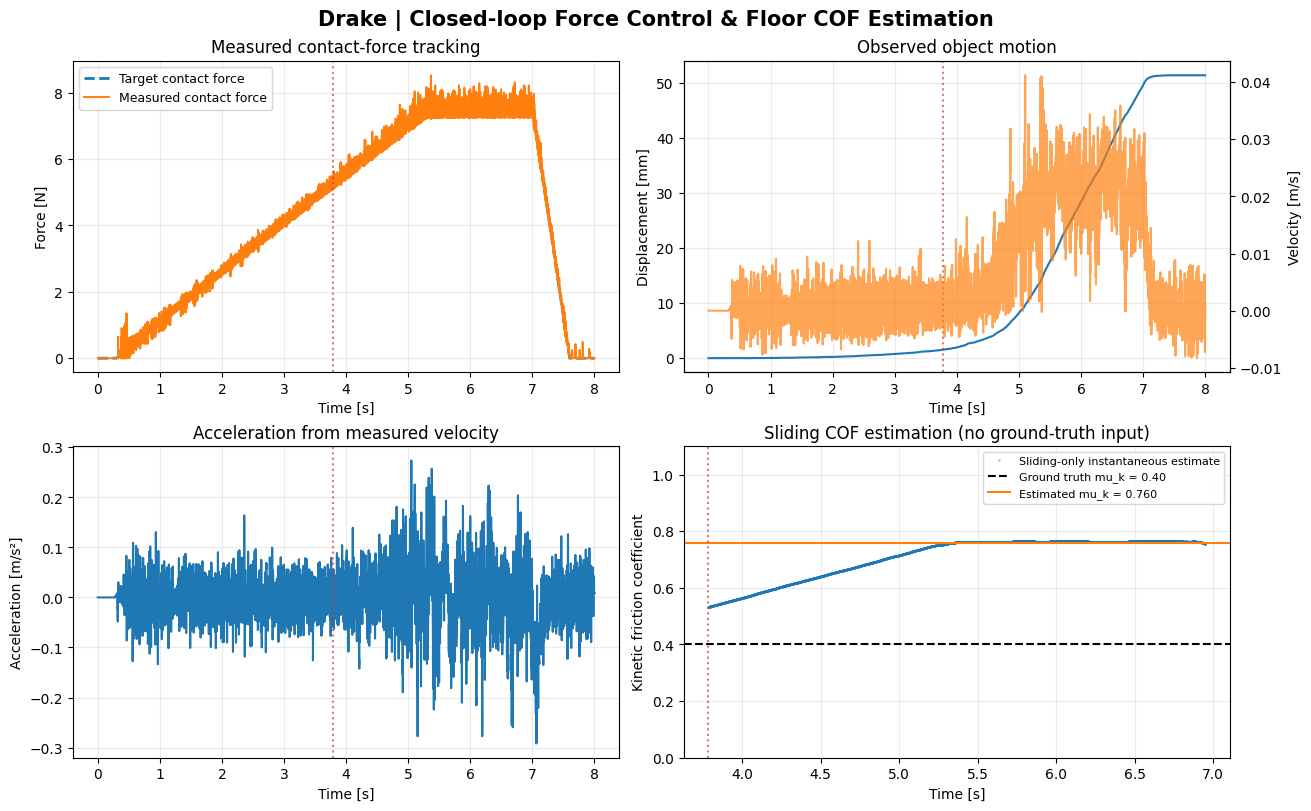


Drake | Closed-loop Force Control & COF Estimation

Physical model
  Free box mass               : 1.000 kg
  Box size (L x W x H)       : 0.200 x 0.160 x 0.080 m
  Sphere mass / radius       : 0.050 kg / 0.020 m
  Sphere motion              : force-actuated prismatic X joint
  Box motion                 : free 6-DOF rigid body
  Controller                 : PI contact force feedback with anti-windup
  Drake contact model       : point contact / discrete MultibodyPlant
  Plant/control time step    : 0.0010 s

Ground truth (for evaluation ONLY)
  True static COF            : 0.5000
  True kinetic COF           : 0.4000

Measured-data estimates
  Estimated static COF       : 0.5166
  Estimated kinetic COF      : 0.7598
  Breakaway time             : 3.7840 s
  Valid sliding samples     : 3164
  Maximum measured force     : 8.526 N
  Maximum box displacement  : 51.40 mm
  Maximum block tilt        : 0.06 deg

Estimation uses only measured sphere->box contact force,
observed block motion 

In [ ]:
"""Closed-loop contact-force COF experiment in Drake.

Run on Google Colab with the accompanying notebook, or in Python 3.12+
with: pip install drake numpy pandas matplotlib

Creates automatically:
    drake_cof_results/force_and_cof.png
    drake_cof_results/scene_animation.html
    drake_cof_results/measurements.csv
    drake_cof_results/summary.txt
    drake_cof_results.zip

No model files and no user edits are required.
"""

from __future__ import annotations

import math
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pydrake.geometry import (
    Box, HalfSpace, Meshcat, MeshcatVisualizer, Sphere,
)
from pydrake.math import RigidTransform
from pydrake.multibody.plant import (
    AddMultibodyPlantSceneGraph, ContactModel, CoulombFriction,
)
from pydrake.multibody.tree import (
    FixedOffsetFrame, PrismaticJoint, SpatialInertia, UnitInertia,
)
from pydrake.systems.analysis import Simulator
from pydrake.systems.framework import DiagramBuilder


# ----------------------------- EXPERIMENT ------------------------------
DT = 0.001                     # Plant integration and force controller period (s)
T_END = 8.0                    # Total simulated duration (s)
BOX_MASS = 1.0                 # kg (KNOWN TO ESTIMATOR)
BOX_LENGTH = 0.20              # m, along pushing axis
BOX_WIDTH = 0.16               # m
BOX_HEIGHT = 0.08              # m
SPHERE_RADIUS = 0.020          # m
SPHERE_MASS = 0.05             # kg
GRAVITY = 9.81                 # m/s^2

# Hidden ground truth. Used by Drake to build the simulation; the
# estimation function never receives these values.
TRUE_MU_STATIC = 0.50
TRUE_MU_DYNAMIC = 0.40

# Force-loop controller (not a position controller).
KP = 0.30                       # N applied per N contact force error
KI = 1.8                      # N/(N*s)
MAX_ACTUATOR_FORCE = 12.0      # N
MIN_ACTUATOR_FORCE = -2.0     # N; motor can pull backward

OUT = Path('drake_cof_results')
OUT.mkdir(exist_ok=True)


def target_force(t: float) -> float:
    """Gradual increase, hold after breakaway, and unload."""
    # Gradual ramp and a long sliding interval, then gentle unload.
    if t < 0.3:
        return 0.0
    if t < 5.3:
        return 7.5 * (t - 0.3) / 5.0
    if t < 7.0:
        return 7.5
    if t < 7.6:
        return 7.5 * (7.6 - t) / 0.6
    return 0.0


def measure_sphere_to_box_contact(plant, plant_context, sphere, block):
    """Read sensor-like x contact force using Drake's ContactResults.

    PointPairContactInfo.contact_force() acts on body B from body A;
    switch the sign when the box is body A.
    """
    results = plant.get_contact_results_output_port().Eval(plant_context)
    fx = 0.0
    for i in range(results.num_point_pair_contacts()):
        p = results.point_pair_contact_info(i)
        a = p.bodyA_index()
        b = p.bodyB_index()
        if a == sphere.index() and b == block.index():
            fx += float(p.contact_force()[0])
        elif a == block.index() and b == sphere.index():
            fx -= float(p.contact_force()[0])
    return fx


def build_simulation():
    builder = DiagramBuilder()
    plant, scene_graph = AddMultibodyPlantSceneGraph(builder, time_step=DT)
    plant.set_contact_model(ContactModel.kPoint)
    # Avoid artificially hard point contacts for this demonstration.
    plant.set_penetration_allowance(0.002)

    # World floor: infinitely wide collision plane, large colored visual pad.
    # Equal coefficients on both contacting surfaces give the intended
    # combined floor-block Coulomb friction.
    friction = CoulombFriction(TRUE_MU_STATIC, TRUE_MU_DYNAMIC)
    plant.RegisterCollisionGeometry(
        plant.world_body(), RigidTransform(), HalfSpace(),
        'floor_collision', friction,
    )
    plant.RegisterVisualGeometry(
        plant.world_body(), RigidTransform([0.9, 0.0, -0.012]),
        Box(6.0, 1.8, 0.024), 'floor_visual',
        np.array([0.71, 0.76, 0.82, 1.0]),
    )

    # Fully floating (6-DOF) rigid block.
    block_inertia = SpatialInertia(
        BOX_MASS, np.zeros(3),
        UnitInertia.SolidBox(BOX_LENGTH, BOX_WIDTH, BOX_HEIGHT),
    )
    block = plant.AddRigidBody('sliding_block', block_inertia)
    plant.RegisterCollisionGeometry(
        block, RigidTransform(), Box(BOX_LENGTH, BOX_WIDTH, BOX_HEIGHT),
        'block_collision', friction,
    )
    plant.RegisterVisualGeometry(
        block, RigidTransform(), Box(BOX_LENGTH, BOX_WIDTH, BOX_HEIGHT),
        'block_visual', np.array([0.90, 0.59, 0.27, 1.0]),
    )

    # Dynamic rigid sphere constrained only to move along the global x-axis.
    sphere_inertia = SpatialInertia(
        SPHERE_MASS, np.zeros(3), UnitInertia.SolidSphere(SPHERE_RADIUS),
    )
    sphere = plant.AddRigidBody('force_sensor_sphere', sphere_inertia)
    # Zero tangential friction between the spherical probe and the block;
    # the unknown friction being inferred is BLOCK-TO-FLOOR.
    probe_friction = CoulombFriction(0.0, 0.0)
    plant.RegisterCollisionGeometry(
        sphere, RigidTransform(), Sphere(SPHERE_RADIUS),
        'sphere_collision', probe_friction,
    )
    plant.RegisterVisualGeometry(
        sphere, RigidTransform(), Sphere(SPHERE_RADIUS),
        'sphere_visual', np.array([0.20, 0.47, 0.92, 1.0]),
    )

    # At zero joint extension the sphere is just to the left of the box.
    sphere_start_x = -BOX_LENGTH / 2 - SPHERE_RADIUS - 0.0001
    track_frame = plant.AddFrame(FixedOffsetFrame(
        'probe_track', plant.world_frame(),
        RigidTransform([sphere_start_x, 0, BOX_HEIGHT / 2]),
    ))
    slider = plant.AddJoint(PrismaticJoint(
        'probe_x_axis', track_frame, sphere.body_frame(),
        np.array([1.0, 0.0, 0.0]),
        damping=0.6,
    ))
    plant.AddJointActuator('probe_force_actuator', slider)
    plant.Finalize()

    # Meshcat records the entire experiment and produces stand-alone HTML.
    meshcat = Meshcat()
    viz = MeshcatVisualizer.AddToBuilder(builder, scene_graph, meshcat)
    diagram = builder.Build()

    simulator = Simulator(diagram)
    root = simulator.get_mutable_context()
    ctx = plant.GetMyMutableContextFromRoot(root)
    plant.SetFreeBodyPose(
        ctx, block, RigidTransform([0.0, 0.0, BOX_HEIGHT / 2]),
    )
    slider.set_translation(ctx, 0.0)
    slider.set_translation_rate(ctx, 0.0)
    actuation_port = plant.get_actuation_input_port()
    actuation_port.FixValue(ctx, np.array([0.0]))
    simulator.Initialize()

    return plant, block, sphere, slider, simulator, ctx, actuation_port, meshcat, viz


def perform_experiment():
    (plant, block, sphere, slider, simulator, ctx, act_port,
     meshcat, viz) = build_simulation()

    logs = []
    integral = 0.0
    previous_cmd = 0.0
    viz.StartRecording()

    print('Running closed-loop Drake force-control simulation...')
    n = int(round(T_END / DT))
    for step in range(n + 1):
        t = float(step * DT)
        # These are sensor observations from the current simulated state.
        f_contact = measure_sphere_to_box_contact(plant, ctx, sphere, block)
        pose = plant.EvalBodyPoseInWorld(ctx, block)
        vel = plant.EvalBodySpatialVelocityInWorld(ctx, block)
        xyz = pose.translation()
        R = pose.rotation().matrix()
        vx = float(vel.translational()[0])
        # Angle between the block's original upright axis and world z.
        tilt = math.degrees(math.acos(float(np.clip(R[2, 2], -1, 1))))
        f_target = target_force(t)

        # PI contact-force feedback with actuator saturation and anti-windup.
        error = f_target - f_contact
        # Include feedforward and measured probe velocity damping.
        # This avoids the violent acceleration seen in the original run.
        probe_speed = float(slider.get_translation_rate(ctx))
        proposal = f_target + KP * error + KI * integral - 1.2 * probe_speed
        f_cmd = float(np.clip(proposal, MIN_ACTUATOR_FORCE, MAX_ACTUATOR_FORCE))
        if ((MIN_ACTUATOR_FORCE < proposal < MAX_ACTUATOR_FORCE)
                or (proposal >= MAX_ACTUATOR_FORCE and error < 0)
                or (proposal <= MIN_ACTUATOR_FORCE and error > 0)):
            integral = float(np.clip(integral + error * DT, -0.6, 0.6))

        logs.append({
            'time_s': t,
            'force_target_N': f_target,
            'contact_force_N': f_contact,
            'actuator_force_N': previous_cmd,
            'next_actuator_force_N': f_cmd,
            'block_x_m': float(xyz[0]),
            'block_y_m': float(xyz[1]),
            'block_z_m': float(xyz[2]),
            'block_vx_m_s': vx,
            'block_vy_m_s': float(vel.translational()[1]),
            'block_vz_m_s': float(vel.translational()[2]),
            'tilt_deg': tilt,
            'sphere_x_m': float(sphere_start := (
                -BOX_LENGTH / 2 - SPHERE_RADIUS - 0.0001
                + slider.get_translation(ctx))),
            'sphere_vx_m_s': float(slider.get_translation_rate(ctx)),
        })
        if step == n:
            break
        act_port.FixValue(ctx, np.array([f_cmd]))
        simulator.AdvanceTo(float((step + 1) * DT))
        previous_cmd = f_cmd
        if step > 0 and step % 500 == 0:
            print(f'   simulated {t:4.1f}/{T_END:.1f} s')

    viz.StopRecording()
    viz.PublishRecording()
    try:
        (OUT / 'scene_animation.html').write_text(
            meshcat.StaticHtml(), encoding='utf-8',
        )
        print('3D animation: scene_animation.html')
    except Exception as exc:
        print(f'Could not export standalone 3D HTML: {exc}')
        print(f'Live Meshcat: {meshcat.web_url()}')
    return pd.DataFrame(logs)


def estimate_cof(data):
    """Estimate from sphere->box measured force and observed box motion ONLY.

    The old code required vx > 0.04 m/s, while the measured maximum was
    only 0.026 m/s. Instead, estimate sustained velocity from a 0.12 s
    displacement baseline and friction using *integrated momentum*, avoiding
    numerical differentiation of noisy instantaneous velocities.
    """
    t = data['time_s'].to_numpy()
    x = data['block_x_m'].to_numpy()
    vx = data['block_vx_m_s'].to_numpy()
    fc = data['contact_force_N'].to_numpy()
    tilt = data['tilt_deg'].to_numpy()
    dt = float(np.median(np.diff(t)))
    n = len(t)
    # Smooth box position in the *observation layer* (not in Drake dynamics).
    def smooth(a, w):
        return np.convolve(np.pad(a, (w//2, w//2), mode='edge'),
                           np.ones(w)/w, mode='valid')
    x_filt = smooth(x, 51 if n>51 else 5)
    half = max(2, int(round(0.06 / dt)))
    # +/-60 ms symmetric finite difference of averaged displacement.
    v_displacement = (np.roll(x_filt, -half) - np.roll(x_filt, half)) / (2*half*dt)
    v_displacement[:half] = (x_filt[half:2*half]-x_filt[:half])/(half*dt)
    v_displacement[-half:] = (x_filt[-half:]-x_filt[-2*half:-half])/(half*dt)

    # Smooth recorded velocity as an independent sanity check.
    v_smooth = smooth(vx, 101 if n>101 else 5)
    ax = np.gradient(v_smooth, dt)
    # Motion must persist (not the 1-2 ms transient solver chatter).
    speed_threshold = 0.0015  # 1.5 mm/s, not the previous 40 mm/s
    candidate = ((v_displacement > speed_threshold) &
                 (x-x[0] > 0.0003) & (fc > 0.5) & (tilt < 3.0) &
                 (t > 0.35) & (t < 6.9))
    good_motion = smooth(candidate.astype(float), 101 if n>101 else 5) > 0.82
    onset_idx = np.flatnonzero(good_motion)
    if len(onset_idx):
        i0 = int(onset_idx[0])
        breakaway_t = float(t[i0])
        # Local force average just before sustained motion, not a spike peak.
        pre = (t >= breakaway_t-0.16) & (t <= breakaway_t-0.02)
        mu_static = float(np.median(fc[pre])/(BOX_MASS*GRAVITY)) if np.count_nonzero(pre)>8 else float('nan')
    else:
        i0 = None
        breakaway_t = float('nan')
        mu_static = float('nan')

    # Integrated dynamics in each 0.25-s window:
    # mu = [integral(F_contact dt) - m*(v_end-v_start)] / (m*g*T).
    # Unlike differentiating raw velocity, this is numerically well-behaved.
    W = max(10, int(round(0.25/dt)))
    w2 = W//2
    rolling_force = smooth(fc, W + (W%2==0))
    dynamic_est = np.full(n, np.nan)
    sliding = np.zeros(n,dtype=bool)
    for i in range(w2, n-w2):
        a,b=i-w2,i+w2
        if b>=n or b<=a:continue
        vbar = (x_filt[b]-x_filt[a])/(t[b]-t[a])
        if not (vbar>speed_threshold and t[i]>0.7 and t[i]<6.95
                and tilt[a:b].max()<3.0 and np.mean(fc[a:b])>1.5
                and (x_filt[b]-x_filt[a])>0.00038):
            continue
        # Window-average measured force minus measured momentum derivative.
        avg_force = float(np.mean(fc[a:b]))
        momentum_rate = BOX_MASS*(v_smooth[b]-v_smooth[a])/(t[b]-t[a])
        mu = (avg_force-momentum_rate)/(BOX_MASS*GRAVITY)
        if np.isfinite(mu) and 0 <= mu <= 1.5:
            sliding[i]=True
            dynamic_est[i]=mu
    if np.count_nonzero(sliding)>=15:
        mu_dynamic=float(np.median(dynamic_est[sliding]))
    else:
        mu_dynamic=float('nan')
    data['block_vx_displacement_filtered_m_s']=v_displacement
    data['block_ax_m_s2_estimated']=ax
    data['instantaneous_mu_dynamic_estimate']=dynamic_est
    data['sliding_sample']=sliding
    return mu_static,mu_dynamic,breakaway_t,sliding


def make_outputs(data, mu_static, mu_dynamic, breakaway_t, sliding):
    data.to_csv(OUT / 'measurements.csv', index=False)
    t = data['time_s'].to_numpy()

    fig, ax = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
    fig.suptitle('Drake | Closed-loop Force Control & Floor COF Estimation',
                 fontsize=15, fontweight='bold')

    ax[0, 0].plot(t, data['force_target_N'], '--', lw=2, label='Target contact force')
    ax[0, 0].plot(t, data['contact_force_N'], lw=1.4, label='Measured contact force')
    ax[0, 0].set_ylabel('Force [N]')
    ax[0, 0].set_title('Measured contact-force tracking')
    ax[0, 0].legend(fontsize=9)

    ax[0, 1].plot(t, 1000 * data['block_x_m'], label='Block x [mm]')
    ax[0, 1].set_ylabel('Displacement [mm]')
    ax[0, 1].set_title('Observed object motion')
    a2 = ax[0, 1].twinx()
    a2.plot(t, data['block_vx_m_s'], color='tab:orange', alpha=0.7,
            label='Block velocity')
    a2.set_ylabel('Velocity [m/s]')

    ax[1, 0].plot(t, data['block_ax_m_s2_estimated'], label='Estimated acceleration')
    ax[1, 0].set_ylabel('Acceleration [m/s²]')
    ax[1, 0].set_title('Acceleration from measured velocity')

    ax[1, 1].plot(t, data['instantaneous_mu_dynamic_estimate'], '.',
                  alpha=0.30, ms=2, label='Sliding-only instantaneous estimate')
    ax[1, 1].axhline(TRUE_MU_DYNAMIC, color='k', ls='--',
                      label=f'Ground truth mu_k = {TRUE_MU_DYNAMIC:.2f}')
    if np.isfinite(mu_dynamic):
        ax[1, 1].axhline(mu_dynamic, color='tab:orange',
                          label=f'Estimated mu_k = {mu_dynamic:.3f}')
    ax[1, 1].set_ylim(0, 1.1)
    ax[1, 1].set_ylabel('Kinetic friction coefficient')
    ax[1, 1].set_title('Sliding COF estimation (no ground-truth input)')
    ax[1, 1].legend(fontsize=8, loc='upper right')

    for a in ax.flat:
        a.grid(True, alpha=0.25)
        a.set_xlabel('Time [s]')
        if np.isfinite(breakaway_t):
            a.axvline(breakaway_t, color='tab:red', alpha=0.65, ls=':')

    # Do not show a fake COF estimate if there is no identifiable sliding.
    fig.savefig(OUT / 'force_and_cof.png', dpi=180)
    plt.show()
    plt.close(fig)

    def fmt(v):
        return f'{v:.4f}' if np.isfinite(v) else 'NOT IDENTIFIED'

    summary = f'''Drake | Closed-loop Force Control & COF Estimation
{'=' * 58}

Physical model
  Free box mass               : {BOX_MASS:.3f} kg
  Box size (L x W x H)       : {BOX_LENGTH:.3f} x {BOX_WIDTH:.3f} x {BOX_HEIGHT:.3f} m
  Sphere mass / radius       : {SPHERE_MASS:.3f} kg / {SPHERE_RADIUS:.3f} m
  Sphere motion              : force-actuated prismatic X joint
  Box motion                 : free 6-DOF rigid body
  Controller                 : PI contact force feedback with anti-windup
  Drake contact model       : point contact / discrete MultibodyPlant
  Plant/control time step    : {DT:.4f} s

Ground truth (for evaluation ONLY)
  True static COF            : {TRUE_MU_STATIC:.4f}
  True kinetic COF           : {TRUE_MU_DYNAMIC:.4f}

Measured-data estimates
  Estimated static COF       : {fmt(mu_static)}
  Estimated kinetic COF      : {fmt(mu_dynamic)}
  Breakaway time             : {fmt(breakaway_t)} s
  Valid sliding samples     : {np.count_nonzero(sliding)}
  Maximum measured force     : {data['contact_force_N'].max():.3f} N
  Maximum box displacement  : {(data['block_x_m'].max()-data['block_x_m'].iloc[0])*1000:.2f} mm
  Maximum block tilt        : {data['tilt_deg'].max():.2f} deg

Estimation uses only measured sphere->box contact force,
observed block motion (position and velocity), known box mass,
and gravity. It does NOT read the configured friction coefficients.

Interpretation cautions
  - Breakaway threshold in a compliant, time-discretized contact model
    is an approximation to ideal static friction.
  - Kinetic estimate assumes mostly horizontal translation,
    little vertical acceleration and near-mg floor normal load.
  - If a result is 'NOT IDENTIFIED', the necessary sustained slip
    or motion was not observed; no fabricated estimate is reported.
'''
    (OUT / 'summary.txt').write_text(summary, encoding='utf-8')
    print('\n' + summary)
    shutil.make_archive('drake_cof_results', 'zip', root_dir='.',
                        base_dir=OUT.name)
    print(f'All results saved to: {OUT.resolve()}')
    print(f'Zip: {(Path.cwd() / "drake_cof_results.zip").resolve()}')


def main():
    data = perform_experiment()
    mu_s, mu_k, t_break, sliding = estimate_cof(data)
    make_outputs(data, mu_s, mu_k, t_break, sliding)


main()


In [ ]:
from IPython.display import FileLink, display
display(FileLink("drake_cof_results.zip"))
try:
    from google.colab import files
    files.download("drake_cof_results.zip")
except ImportError:
    pass


/content/drake_cof_results.zip

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>